### Setups

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, cohen_kappa_score, precision_score, recall_score
from matplotlib.patches import Patch

Path("../figures/boxplots").mkdir(exist_ok=True)

### Load data

In [2]:
# Majority
#P_MAJ_ALL = "pcm_models_results/personai/majority_class_parrot_all_user_results.json"
#D_MAJ_ALL = "pcm_models_results/dorn/majority_class_parrot_all_user_results.json" 

# PCM model(found in the notebook generate_confusion_matrix.ipynb, but setting both to random_forest)       
P_PCM_ALL = "../../PCM/results/personai/random_forest_all_user_results.json"       
P_PCM_CLASS_PARROT_ALL = "../../PCM/results/personai/majority_class_parrot_all_user_results.json"
P_PCM_DIST_PARROT_ALL = "../../PCM/results/personai/distribution_parrot_all_user_results.json"
D_PCM_ALL = "../../PCM/results/dorn/random_forest_all_user_results.json"
D_PCM_CLASS_PARROT_ALL = "../../PCM/results/dorn/majority_class_parrot_all_user_results.json"
D_PCM_DIST_PARROT_ALL = "../../PCM/results/dorn/distribution_parrot_all_user_results.json"

#Best Cohort Model Warm
P_BEST_COHORT_ALL = "../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey/meta.json"
D_BEST_COHORT_ALL = "../../Experiments/dorn_warm/dorn_warm_Dist_Cross/meta.json"
personai_best_exp = "../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey"
dorn_best_exp = "../../Experiments/dorn_warm/dorn_warm_Dist_Cross"

#Best Cohort Model Cold
P_BEST_COHORT_ALL_COLD = "../../Experiments/PersonAI_cold/PersonAI_cold_sex/meta.json"
D_BEST_COHORT_ALL_COLD = "../../Experiments/dorn_cold/dorn_cold_emotional_stability/meta.json"
personai_best_exp_cold = "../../Experiments/PersonAI_cold/PersonAI_cold_sex"
dorn_best_exp_cold = "../../Experiments/dorn_cold/dorn_cold_emotional_stability"


### helper functions

In [3]:
from statistics import median


def load_pcm_like_metrics(all_user_results_json):
    d = json.load(open(all_user_results_json, "r", encoding="utf-8"))
    users = d["all_users_results"]

    f1_micro = []
    f1_macro = []
    kappa = []
    precision_macro = []
    recall_macro = []

    for u in users:
        f1_micro.append(users[u]["average_f1_micro_over_all_folds"])
        f1_macro.append(users[u]["average_f1_macro_over_all_folds"])
        kappa.append(users[u]["average_kappa_quadratic_over_all_folds"])

        fold_precisions = []
        fold_recalls = []

        for y_true, y_pred in zip(users[u]["k_folds_y_test"], users[u]["k_folds_y_pred"]):
            fold_precisions.append(
                precision_score(y_true, y_pred, average="macro", zero_division=0)
            )
            fold_recalls.append(
                recall_score(y_true, y_pred, average="macro", zero_division=0)
            )

        precision_macro.append(np.mean(fold_precisions))
        recall_macro.append(np.mean(fold_recalls))

    return np.array(f1_micro), np.array(f1_macro), np.array(kappa), np.array(precision_macro), np.array(recall_macro)

def cohort_user_metrics(dataset_name, exp_dir, baseline=False, majority=False):
    exp_dir = Path(exp_dir)

    dfs = []
    for iter_dir in exp_dir.iterdir():
        if not iter_dir.is_dir():
            continue

        if baseline:
            csvs = list(iter_dir.glob("*_baseline_predictions.csv"))
        else:
            csvs = list(iter_dir.glob("*_cluster_predictions.csv"))

        if not csvs:
            continue
        
        df = pd.read_csv(csvs[0])
        df.columns = df.columns.str.strip().str.replace("\ufeff", "")
        dfs.append(df)

    df_all = pd.concat(dfs, ignore_index=True)

    f1_micro = []
    f1_macro = []
    kappa_quad = []
    precision_macro = []
    recall_macro = []

    for u, g in df_all.groupby("user"):
        if majority:
            y_true = g["true"].astype(int).to_numpy()
            y_pred = g["majority_pred"].astype(int).to_numpy()
        else:
            y_true = g["true"].astype(int).to_numpy()
            y_pred = g["pred"].astype(int).to_numpy()

        f1_micro.append(f1_score(y_true, y_pred, average="micro"))
        f1_macro.append(f1_score(y_true, y_pred, average="macro"))
        kappa_quad.append(cohen_kappa_score(y_true, y_pred, weights="quadratic"))
        precision_macro.append(precision_score(y_true, y_pred,average="macro", zero_division=0))
        recall_macro.append(recall_score(y_true, y_pred,average="macro", zero_division=0))

    return np.array(f1_micro), np.array(f1_macro), np.array(kappa_quad), np.array(precision_macro), np.array(recall_macro)

def evaluate_experiment(dataset_name, exp_path, baseline=False):
    exp_path = Path(exp_path)

    all_true = []
    all_pred = []
    micro_f1 = []
    macro_f1 = []

    for iter_dir in exp_path.iterdir():
        if not iter_dir.is_dir():
            continue

        if baseline:
            csv_files = list(iter_dir.glob("*_baseline_predictions.csv"))
        else:
            csv_files = list(iter_dir.glob("*_cluster_predictions.csv"))

        if not csv_files:
            continue

        df = pd.read_csv(csv_files[0])
        for user in df["user"].unique():
            user_df = df[df["user"] == user]
            all_true.extend(user_df["true"])
            all_pred.extend(user_df["pred"])

            macro_f1.append(f1_score(all_true, all_pred, average="macro"))
            micro_f1.append(f1_score(all_true, all_pred, average="micro"))
        


    return median(macro_f1), median(micro_f1)


def top_n_cohort_experiments(dataset_name,root_dir, n=3, ignore_substrings=None, baseline=False):
    root_dir = Path(root_dir)
    ignore_substrings = ignore_substrings or []

    scored = []
    for exp in root_dir.iterdir():
        if not exp.is_dir():
            continue
        if any(s in str(exp) for s in ignore_substrings):
            continue

        macro_f1, micro_f1 = evaluate_experiment(dataset_name, exp, baseline=baseline)
        scored.append((float(micro_f1), exp))

    scored.sort(key=lambda x: x[0], reverse=True)
    return scored[:n]



### find top 3 cohorts

In [4]:
'''top3_dorn = top_n_cohort_experiments("dorn", r"cohort_experiments/dorn", n=3)
top3_personai = top_n_cohort_experiments("personai", r"cohort_experiments/personai", n=3, ignore_substrings=["cold"])

print("Top 3 DORN:")
for macro_f1, micro_f1, p in top3_dorn:
    print(f"{p}: {macro_f1}")

print("Top 3 PersonAI:")
for macro_f1, micro_f1, p in top3_personai:
    print(f"{p}: {macro_f1}")'''


p_macro_f1, p_micro_f1 = evaluate_experiment("personai", personai_best_exp, baseline=False)
print(f"{personai_best_exp}: Macro F1 = {p_macro_f1}, Micro F1 = {p_micro_f1}")
p_macro_f1_b, p_micro_f1_b = evaluate_experiment("personai", personai_best_exp, baseline=True)
print(f"{personai_best_exp} (baseline): Macro F1 = {p_macro_f1_b}, Micro F1 = {p_micro_f1_b}")

d_macro_f1, d_micro_f1 = evaluate_experiment("dorn", dorn_best_exp, baseline=False)
print(f"{dorn_best_exp}: Macro F1 = {d_macro_f1}, Micro F1 = {d_micro_f1}")
d_macro_f1_b, d_micro_f1_b = evaluate_experiment("dorn", dorn_best_exp, baseline=True)
print(f"{dorn_best_exp} (baseline): Macro F1 = {d_macro_f1_b}, Micro F1 = {d_micro_f1_b}")



../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey: Macro F1 = 0.35101858109271744, Micro F1 = 0.7226253459035115
../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey (baseline): Macro F1 = 0.30879703188356167, Micro F1 = 0.6854945240966951
../../Experiments/dorn_warm/dorn_warm_Dist_Cross: Macro F1 = 0.399125551832139, Micro F1 = 0.654945054945055
../../Experiments/dorn_warm/dorn_warm_Dist_Cross (baseline): Macro F1 = 0.2722129211350841, Micro F1 = 0.4453463203463204


In [5]:
top3_dorn = top_n_cohort_experiments("dorn", r"../../Experiments/dorn_cold", n=10)
top3_personai = top_n_cohort_experiments("PersonAI", r"../../Experiments/PersonAI_cold", n=10)

print("Top 10 DORN:")
for micro_f1, p in top3_dorn:
    print(f"{p}: {micro_f1}")

print("Top 10 PersonAI:")
for micro_f1, p in top3_personai:
    print(f"{p}: {micro_f1}")


#dorn_cold_emotional_stability: 0.569925444925445
#PersonAI_cold_sex: 0.6997790868924889


p_macro_f1, p_micro_f1 = evaluate_experiment("personai", personai_best_exp_cold, baseline=False)
print(f"{personai_best_exp_cold}: Macro F1 = {p_macro_f1}, Micro F1 = {p_micro_f1}")
p_macro_f1_b, p_micro_f1_b = evaluate_experiment("personai", personai_best_exp_cold, baseline=True)
print(f"{personai_best_exp_cold} (baseline): Macro F1 = {p_macro_f1_b}, Micro F1 = {p_micro_f1_b}")

d_macro_f1, d_micro_f1 = evaluate_experiment("dorn", dorn_best_exp_cold, baseline=False)
print(f"{dorn_best_exp_cold}: Macro F1 = {d_macro_f1}, Micro F1 = {d_micro_f1}")
d_macro_f1_b, d_micro_f1_b = evaluate_experiment("dorn", dorn_best_exp_cold, baseline=True)
print(f"{dorn_best_exp_cold} (baseline): Macro F1 = {d_macro_f1_b}, Micro F1 = {d_micro_f1_b}")


Top 10 DORN:
../../Experiments/dorn_cold/dorn_cold_survey: 0.5924963924963925
../../Experiments/dorn_cold/dorn_cold_emotional_stability: 0.5910808767951625
../../Experiments/dorn_cold/dorn_cold_openness_to_experiences_wrong: 0.5748524203069658
../../Experiments/dorn_cold/dorn_cold_swls_wrong: 0.5627705627705628
../../Experiments/dorn_cold/dorn_cold_conscientiousness: 0.560482374768089
../../Experiments/dorn_cold/dorn_cold_agreeableness: 0.5505050505050505
../../Experiments/dorn_cold/dorn_cold_big5_wrong: 0.5492063492063493
../../Experiments/dorn_cold/dorn_cold_sex: 0.5414862914862915
../../Experiments/dorn_cold/dorn_cold_sex_wrong: 0.5402708402708403
../../Experiments/dorn_cold/dorn_cold_big5: 0.5353019995877139
Top 10 PersonAI:
../../Experiments/PersonAI_cold/PersonAI_cold_bfi2s_agreeableness_wrong: 0.7077668340146589
../../Experiments/PersonAI_cold/PersonAI_cold_swls_score_filtered: 0.7064134119564072
../../Experiments/PersonAI_cold/PersonAI_cold_swls_score: 0.7039399012253893
../../

### metrics overview

In [6]:
D_maj_micro, D_maj_macro, D_maj_kappa, D_maj_pre, D_maj_recall = load_pcm_like_metrics(D_PCM_CLASS_PARROT_ALL)
D_dist_micro, D_dist_macro, D_dist_kappa, D_dist_pre, D_dist_recall = load_pcm_like_metrics(D_PCM_DIST_PARROT_ALL)

D_pcm_micro, D_pcm_macro, D_pcm_kappa, D_pcm_pre, D_pcm_recall = load_pcm_like_metrics(D_PCM_ALL)
D_co_micro, D_co_macro, D_co_kappa, D_co_pre, D_co_recall = cohort_user_metrics("dorn", dorn_best_exp)
D_co_micro_b, D_co_macro_b, D_co_kappa_b, D_co_pre_b, D_co_recall_b = cohort_user_metrics("dorn", dorn_best_exp, baseline=True)
D_co_micro_m, D_co_macro_m, D_co_kappa_m, D_co_pre_m, D_co_recall_m = cohort_user_metrics("dorn", dorn_best_exp, majority=True)

D_co_micro_cold, D_co_macro_cold, D_co_kappa_cold, D_co_pre_cold, D_co_recall_cold = cohort_user_metrics("dorn", dorn_best_exp_cold)

print("DORN users (majority):", len(D_co_macro_m))
print("DORN users (pcm):", len(D_pcm_macro))
print("DORN users (cohort):", len(D_co_macro))
print("DORN users (cohort baseline):", len(D_co_macro_b))
print("DORN users (cohort cold):", len(D_co_macro_cold))

P_maj_micro, P_maj_macro, P_maj_kappa, P_maj_pre, P_maj_recall = load_pcm_like_metrics(P_PCM_CLASS_PARROT_ALL)
P_dist_micro, P_dist_macro, P_dist_kappa, P_dist_pre, P_dist_recall = load_pcm_like_metrics(P_PCM_DIST_PARROT_ALL)

P_pcm_micro, P_pcm_macro, P_pcm_kappa, P_pcm_pre, P_pcm_recall = load_pcm_like_metrics(P_PCM_ALL)
P_co_micro, P_co_macro, P_co_kappa, P_co_pre, P_co_recall = cohort_user_metrics("personai", personai_best_exp)
P_co_micro_b, P_co_macro_b, P_co_kappa_b, P_co_pre_b, P_co_recall_b = cohort_user_metrics("personai", personai_best_exp, baseline=True)
P_co_micro_m, P_co_macro_m, P_co_kappa_m, P_co_pre_m, P_co_recall_m = cohort_user_metrics("personai", personai_best_exp, majority=True)

P_co_micro_cold, P_co_macro_cold, P_co_kappa_cold, P_co_pre_cold, P_co_recall_cold = cohort_user_metrics("personai", personai_best_exp_cold)

print("PersonAI users (majority):", len(P_co_macro_m))
print("PersonAI users (pcm):", len(P_pcm_macro))
print("PersonAI users (cohort):", len(P_co_macro))
print("PersonAI users (cohort baseline):", len(P_co_macro_b))
print("PersonAI users (cohort cold):", len(P_co_macro_cold))

DORN users (majority): 20
DORN users (pcm): 20
DORN users (cohort): 20
DORN users (cohort baseline): 20
DORN users (cohort cold): 20
PersonAI users (majority): 72
PersonAI users (pcm): 72
PersonAI users (cohort): 72
PersonAI users (cohort baseline): 72
PersonAI users (cohort cold): 72


### Macro F1 boxplot

/tmp/ipykernel_41393/529147499.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


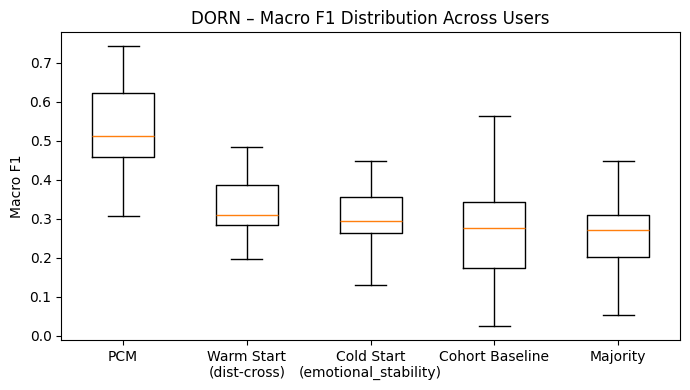

/tmp/ipykernel_41393/529147499.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


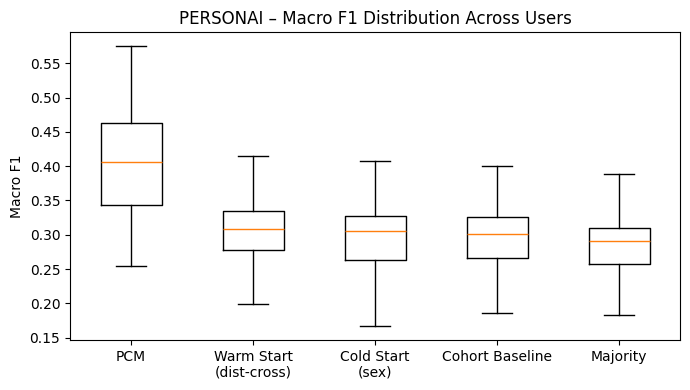

In [7]:
for  dataset in ["dorn", "personai"]:   
    if dataset == "dorn":
        data = [D_pcm_macro, D_co_macro, D_co_macro_cold, D_co_macro_b, D_co_macro_m]
        labels = ["PCM", "Warm Start\n(dist-cross)", "Cold Start\n(emotional_stability)", "Cohort Baseline", "Majority"]
    else:
        data = [P_pcm_macro, P_co_macro, P_co_macro_cold, P_co_macro_b, P_co_macro_m]
        labels = ["PCM", "Warm Start\n(dist-cross)", "Cold Start\n(sex)", "Cohort Baseline", "Majority"]
    plt.figure(figsize=(7,4))
    plt.boxplot(data, labels=labels, showfliers=False)
    plt.ylabel("Macro F1")
    plt.title(f"{dataset.upper()} – Macro F1 Distribution Across Users")
    plt.grid(False)
    plt.tight_layout()
    plt.grid(False)
    plt.savefig(f"../figures/boxplots/{dataset}_macro_f1_models.pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


### Micro/Macro gap

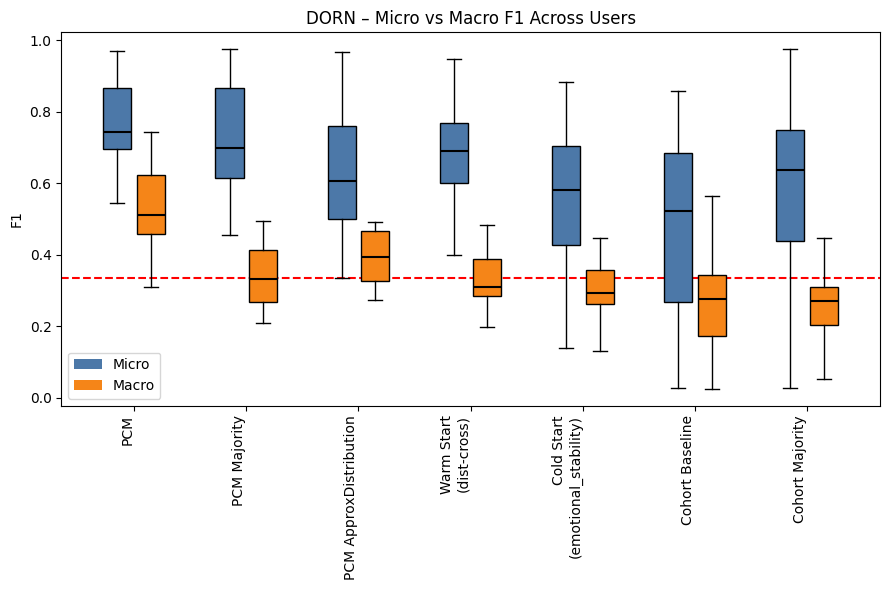

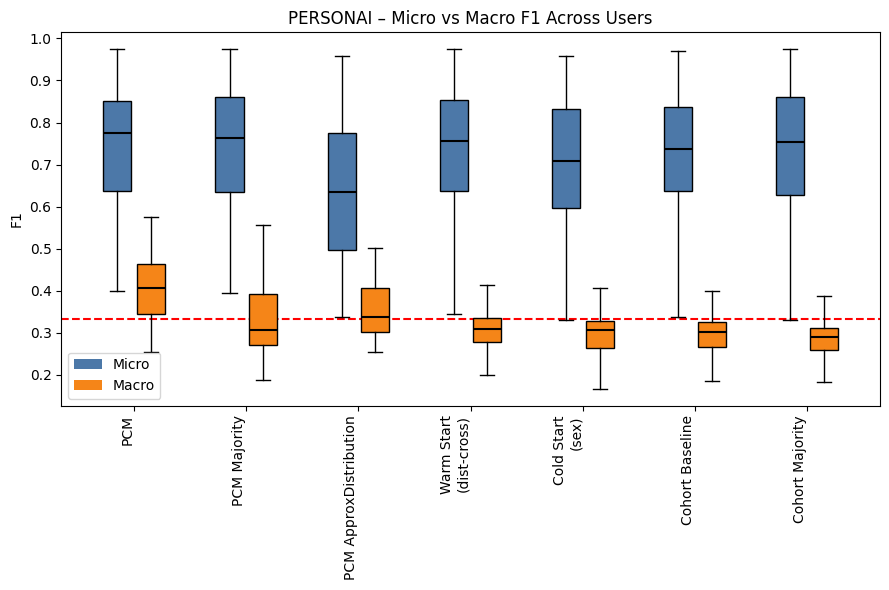

In [8]:
for dataset in ["dorn", "personai"]:
    if dataset == "dorn":    
        data = [D_pcm_micro, D_pcm_macro,D_maj_micro, D_maj_macro, D_dist_micro, D_dist_macro, D_co_micro, D_co_macro, D_co_micro_cold, D_co_macro_cold, D_co_micro_b, D_co_macro_b
            , D_co_micro_m, D_co_macro_m,
         ]
    else:
        data = [P_pcm_micro, P_pcm_macro, P_maj_micro, P_maj_macro, P_dist_micro, P_dist_macro, P_co_micro, P_co_macro, P_co_micro_cold, P_co_macro_cold, P_co_micro_b, P_co_macro_b
            , P_co_micro_m, P_co_macro_m,
                ]

    labels = ["PCM micro","PCM macro", "PCM Majority micro","PCM Majority macro", "PCM Dist micro","PCM Dist macro", "Cohort Warm micro","Cohort Warm macro", "Cohort Cold micro", "Cohort Cold macro", "Cohort Baseline micro", "Cohort Baseline macro"
        , "Cohort Majority micro","Cohort Majority macro",
        ]
    positions = [1,1.3, 2,2.3, 3,3.3, 4,4.3, 5,5.3, 6,6.3, 7,7.3]

    plt.figure(figsize=(9,6))

    bp = plt.boxplot(data, positions=positions, widths=0.25, showfliers=False, patch_artist=True, medianprops=dict(color="black", linewidth=1.5))

    for i, box in enumerate(bp["boxes"]):
        if i % 2 == 0:
            box.set_facecolor("#4C78A8") #micro
        else:
            box.set_facecolor("#F58518") #macro

    if dataset == "dorn":
        plt.xticks([1.15, 2.15, 3.15, 4.15, 5.15, 6.15, 7.15], ["PCM", "PCM Majority", "PCM ApproxDistribution", "Warm Start\n(dist-cross)", "Cold Start\n(emotional_stability)", "Cohort Baseline"
            , "Cohort Majority"
        ], rotation=25, ha="right")
    if dataset == "personai":
        plt.xticks([1.15, 2.15, 3.15, 4.15, 5.15, 6.15, 7.15], ["PCM", "PCM Majority", "PCM ApproxDistribution", "Warm Start\n(dist-cross)", "Cold Start\n(sex)", "Cohort Baseline",
         "Cohort Majority"
            ], rotation=25, ha="right")

    # for orientation purposes - completely random predictions on a balanced dataset the F1 would be 0.33
    # asdf = np.random.randint(0,3,100000)
    # asdf2 = np.random.randint(0,3,100000)
    # sklearn.metrics.f1_score(asdf, asdf2, average="macro")
    random_f1_balanced = 0.33333333
    plt.axhline(y=random_f1_balanced, color='red', linestyle='--', linewidth=1.5,
            label='threshold', zorder=0)

    plt.ylabel("F1")
    plt.title(f"{dataset.upper()} – Micro vs Macro F1 Across Users")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.legend(loc='lower left', handles=[Patch(facecolor="#4C78A8", label="Micro"), Patch(facecolor="#F58518", label="Macro")])
    plt.grid(False)
    plt.savefig(f"../figures/boxplots/{dataset}_micro_vs_macro_gap_extended.pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    pandas.DataFrame(np.array(data).T, columns=labels).describe().to_csv(f"../figures/boxplots/{dataset}_micro_vs_macro_gap_extended.csv")

### Quadratic Kappa boxplot

/tmp/ipykernel_41393/4005478520.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


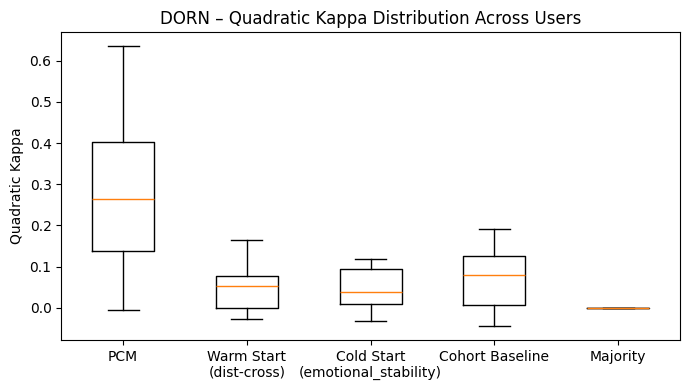

/tmp/ipykernel_41393/4005478520.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


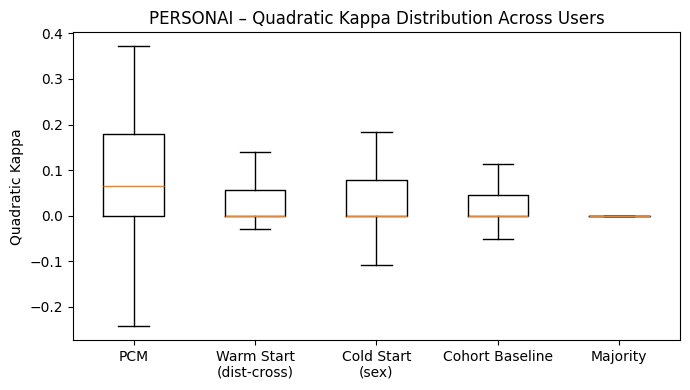

In [9]:
for  dataset in ["dorn", "personai"]:   
    if dataset == "dorn":
        data = [D_pcm_kappa, D_co_kappa, D_co_kappa_cold, D_co_kappa_b, D_co_kappa_m]
        labels = ["PCM", "Warm Start\n(dist-cross)", "Cold Start\n(emotional_stability)", "Cohort Baseline", "Majority"]
    else:
        data = [P_pcm_kappa, P_co_kappa, P_co_kappa_cold, P_co_kappa_b, P_co_kappa_m]
        labels = ["PCM", "Warm Start\n(dist-cross)", "Cold Start\n(sex)", "Cohort Baseline", "Majority"]


    plt.figure(figsize=(7,4))
    plt.boxplot(data, labels=labels, showfliers=False)
    plt.ylabel("Quadratic Kappa")
    plt.title(f"{dataset.upper()} – Quadratic Kappa Distribution Across Users")
    plt.tight_layout()
    plt.grid(False)
    plt.savefig(f"../figures/boxplots/{dataset}_quadratic_kappa_models.pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


### precision

/tmp/ipykernel_41393/1335261251.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


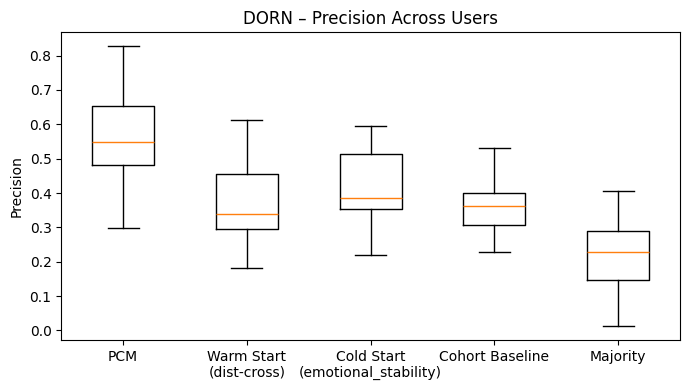

/tmp/ipykernel_41393/1335261251.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


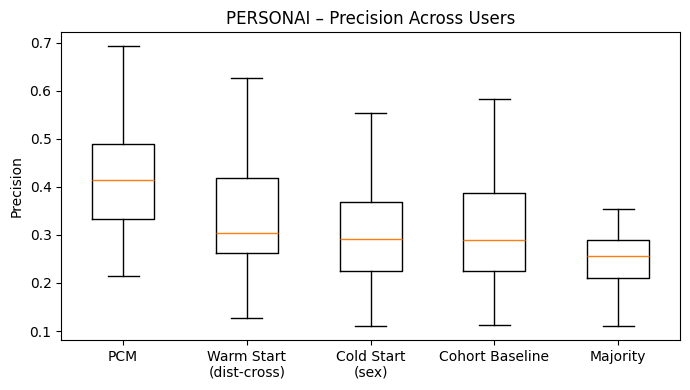

In [10]:
for  dataset in ["dorn", "personai"]:   
    if dataset == "dorn":
        data = [D_pcm_pre, D_co_pre,  D_co_pre_cold, D_co_pre_b, D_co_pre_m]
        labels = ["PCM", "Warm Start\n(dist-cross)", "Cold Start\n(emotional_stability)", "Cohort Baseline", "Majority"]
    else:
        data = [P_pcm_pre, P_co_pre, P_co_pre_cold, P_co_pre_b, P_co_pre_m]
        labels = ["PCM", "Warm Start\n(dist-cross)", "Cold Start\n(sex)", "Cohort Baseline", "Majority"]


    plt.figure(figsize=(7,4))
    plt.boxplot(data, labels=labels, showfliers=False)
    plt.ylabel("Precision")
    plt.title(f"{dataset.upper()} – Precision Across Users")
    plt.tight_layout()
    plt.grid(False)
    plt.savefig(f"../figures/boxplots/{dataset}_precision_models.pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


### recall

/tmp/ipykernel_41393/1918940659.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


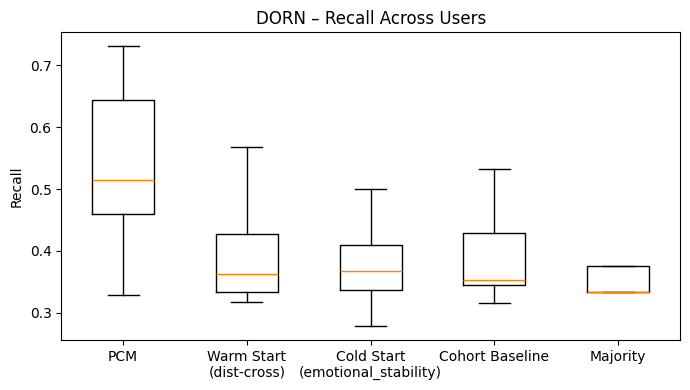

/tmp/ipykernel_41393/1918940659.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


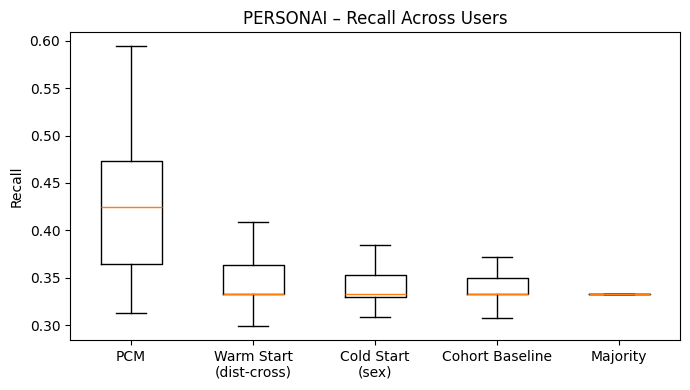

In [11]:
for  dataset in ["dorn", "personai"]:   
    if dataset == "dorn":
        data = [D_pcm_recall, D_co_recall, D_co_recall_cold, D_co_recall_b, D_co_recall_m]
        labels = ["PCM", "Warm Start\n(dist-cross)", "Cold Start\n(emotional_stability)", "Cohort Baseline", "Majority"]
    else:
        data = [P_pcm_recall, P_co_recall, P_co_recall_cold, P_co_recall_b, P_co_recall_m]
        labels = ["PCM", "Warm Start\n(dist-cross)", "Cold Start\n(sex)", "Cohort Baseline", "Majority"]


    plt.figure(figsize=(7,4))
    plt.boxplot(data, labels=labels, showfliers=False)
    plt.ylabel("Recall")
    plt.title(f"{dataset.upper()} – Recall Across Users")
    plt.tight_layout()
    plt.grid(False)
    plt.savefig(f"../figures/boxplots/{dataset}_recall_models.pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
